# 13강 실습: '완전'과 '아주'의 연령별·성별 비교

12강에서는 '완전'과 '아주'가 **무엇 앞에** 오는지를 셌다. 오늘은 **누가** 쓰는지를 센다. 11강의 화자 표(`speakers.csv`)를 발화 표에 이어 붙이고, 나이와 성별로 나누어 두 부사를 비교한다.

**오늘 할 것**

1. 화자 표의 한 행이 무엇을 세는지 따져 본다. 168,267은 사람 수인가?
2. 두 표를 열쇠 두 개(`doc_id`, `speaker_id`)로 이어 붙인다.
3. 크기가 다른 집단을 비율로 비교한다(만 발화당 수, '완전'의 몫).
4. 그 비율이 몇 사람에게서 나왔는지 확인한다.

**시작하기 전에**

- 이 노트북은 저장소 **맨 위**(`/workspaces/LDS2026`)에 두어야 `data/nikl/…` 경로가 맞는다.
- 11강 노트북이 만든 `data/nikl/utterances.csv`와 `data/nikl/speakers.csv`가 있어야 한다. 없으면(Codespace를 새로 만들었다면) 말뭉치 zip을 다시 올리고 `11-json.ipynb`를 [Run All]로 돌린다.
- 오늘은 Kiwi를 쓰지 않는다.
- 커밋하기 전에는 [Restart] 후 [Run All]로 위에서 아래까지 한 번에 돌려 본다.

```bash
cd /workspaces/LDS2026
```

## 0. 준비

세 가지를 불러오고 그림의 바탕을 정한다.

- **pandas**: 7강에서 쓴 표 라이브러리
- **seaborn**, **matplotlib**: 7강의 그리기 도구. `set_theme`에 `font='NanumGothic'`을 주면 그림의 한글이 나온다. 한글이 네모로 나오면 12강처럼 터미널에서 `rm -rf ~/.cache/matplotlib`를 하고 커널을 다시 시작한다.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid', font='NanumGothic')

## 1. 화자 표

11강에서 남긴 화자 표를 다시 읽는다. 이름이 길어 오늘은 `sp`라고 부른다.

- `to_dict()`: `value_counts`의 결과를 `dict`로 바꾸어 한 줄로 찍는다(12강).

나이는 네 구간으로, 성별은 둘로 적혀 있다. **고르게 모이지 않았다.** 20대가 46.5%, 여성이 87.5%이고, 10대와 40대 이상은 합쳐도 17%다.

In [2]:
sp = pd.read_csv('data/nikl/speakers.csv')
print(sp.shape)
print(sp['age'].value_counts().to_dict())
print(sp['sex'].value_counts().to_dict())

(168267, 10)
{'20대': 78318, '30대': 61229, '40대 이상': 18474, '10대': 10246}
{'여성': 147252, '남성': 21015}


나이와 성별을 함께 센다.

- `margins=True`: 행과 열의 합(`All`)을 덧붙인다.

남성은 어느 나이에서나 적다. 10대 남성은 752행으로 10대의 7.3%이고, 40대 이상에서는 16.2%다. **남성은 나이 든 쪽에 조금 더 몰려 있다.** 오늘 내내 이 표를 옆에 둔다.

In [3]:
print(pd.crosstab(sp['age'], sp['sex'], margins=True))

sex        남성      여성     All
age                          
10대       752    9494   10246
20대      7514   70804   78318
30대      9757   51472   61229
40대 이상   2992   15482   18474
All     21015  147252  168267


**168,267은 사람 수인가?** 화자의 속성 여덟 칸(나이, 직업, 성별, 출생지, 주 거주지, 현 거주지, 기기, 자판)이 모두 같으면 같은 번호를 붙여 본다.

- `cols`: 속성 열 이름의 목록
- `groupby(cols).ngroup()`: 묶음마다 0부터 번호를 매겨 행마다 돌려준다. 그 번호를 `who` 열에 둔다.

168,267행이 2,108가지뿐이다. 1006번(20대 학생 여성, 서울, 스마트폰, 2벌식 쿼티)은 3,219행이다. 3,219명일까, 몇 사람이 여러 번 나온 것일까? **이것만으로는 모른다.**

In [4]:
cols = ['age', 'occupation', 'sex', 'birthplace',
        'principal_residence', 'current_residence', 'device', 'keyboard']
sp['who'] = sp.groupby(cols).ngroup()
print(sp['who'].nunique())
print(sp['who'].value_counts().head(3))

2108
who
1006    3219
902     2177
1560    1800
Name: count, dtype: int64


2인 대화(파일 이름이 `MD`로 시작한다, 11강)만 골라, 대화마다 두 화자의 번호를 짝짓는다.

- `str.startswith('MD')`: 그 글자로 시작하는지
- `agg(['min', 'max'])`: 셈 여러 개를 한 번에 한다. 여기서는 대화마다 두 화자 번호의 작은 것과 큰 것. 작은 것, 큰 것 순으로 적으면 누가 1번 화자였든 같은 짝이 된다.
- 표의 `value_counts()`: (작은 것, 큰 것) **짝**을 센다.

2인 대화 62,491건 가운데 692건이 1779번과 1962번의 대화다.

In [5]:
md = sp[sp['doc_id'].str.startswith('MD')]
pairs = md.groupby('doc_id')['who'].agg(['min', 'max'])
print(len(pairs))
print(pairs.value_counts().head(3))

62491
min   max 
1779  1962    692
462   1006    585
568   641     525
Name: count, dtype: int64


그 두 번호의 속성을 본다.

- `set_index('who')`: `who` 열을 색인으로 올린다.
- `drop_duplicates()`: 같은 행은 하나만 남긴다.
- `.T`: 행과 열을 뒤바꾼다. 열이 많은 행 둘을 세로로 세워 비교한다.

40대 이상의 여성과 남성이다. 나고(경기), 오래 살고(인천), 지금 사는 곳(경기)이 같고, 기기와 자판도 같다. **같은 두 사람이 692번 대화했다**고 보는 편이 자연스럽다.

**화자 표의 한 행은 '대화 하나 속의 화자 하나'다.** 같은 사람이 대화를 여러 번 보내면 그때마다 행이 새로 생긴다. 말뭉치는 개인 정보를 지우면서 사람에게 번호를 주지 않았다. 그래서 168,267은 사람 수가 아니다. 여성 87.5%도 사람의 비율이 아니라 '대화 속 화자'의 비율이다.

**`who`는 사람의 조작적 정의다.** 속성 여덟 칸이 모두 같으면 같은 사람으로 친다. 12강의 품사 묶음처럼, 정하고 적어 둔다.

- 너무 많이 묶을 수 있다. 서울의 20대 여학생은 아마 여럿이다.
- 너무 적게 묶을 수 있다. 같은 사람도 기기를 바꾸거나 나이 구간을 넘으면 둘이 된다.

그래도 한 사람이 수를 얼마나 끌고 가는지는 가늠할 수 있다(5절).

In [6]:
two = sp[sp['who'].isin([1779, 1962])]
print(two.set_index('who')[cols].drop_duplicates().T)

who                     1779     1962
age                   40대 이상   40대 이상
occupation             가정 주부   사무 종사자
sex                       여성       남성
birthplace                경기       경기
principal_residence       인천       인천
current_residence         경기       경기
device                  스마트폰     스마트폰
keyboard             2벌식(쿼티)  2벌식(쿼티)


## 2. 표 잇기

**발화마다 화자를 찾아 붙인다.** 7강에서는 레시피 번호 `number` 하나로 권 이름을 붙였다. 오늘은 `doc_id`와 `speaker_id`가 **둘 다** 같은 행끼리 짝짓는다(11강의 '열쇠는 두 열'). 발화 여럿이 화자 하나를 가리키므로 여럿 대 하나(many-to-one)의 잇기다. 11강에서 표를 둘로 나눈 까닭이 이것이었다. 나이와 성별은 필요할 때 찾아 붙인다.

- `on`: 열쇠 열의 목록. 모두 같아야 짝이 된다.
- `how='left'`: 왼쪽(발화) 행을 짝이 없어도 모두 남긴다. 짝이 없으면 `NaN`이 된다.
- `validate='many_to_one'`: 오른쪽(화자) 열쇠가 겹치지 않는지 확인하고, 겹치면 멈춘다.

행 수가 그대로이고 `age`의 `NaN`이 0이면 **모든 발화가 화자를 하나씩 찾은 것**이다.

**열쇠가 하나뿐이면.** `u.merge(sp, on='speaker_id', validate='many_to_one')`은 `MergeError: Merge keys are not unique in right dataset; not a many-to-one merge`를 내고 멈춘다(이 줄은 노트북에 넣지 않았다). `validate`가 없었다면 1번 화자의 발화 1,418,839개가 화자 표의 '1번 화자' 74,665행 모두와 짝지어진다. 모두 합하면 약 2,101억 행이다. 멈추지 않고 메모리를 다 쓴 뒤에야 커널이 죽는다. `validate`는 **내가 생각한 짜임**을 코드로 적어 두는 것이다.

In [7]:
u = pd.read_csv('data/nikl/utterances.csv')
u = u.merge(sp[['doc_id', 'speaker_id', 'age', 'sex', 'who']],
            on=['doc_id', 'speaker_id'], how='left',
            validate='many_to_one')
print(u.shape)
print(u['age'].isna().sum())

(2977840, 9)
0


## 3. 나이로 나누기

**발화마다 세어 둔다.** 12강의 `\b` 셈 그대로다. 12강에서는 `.sum()`으로 바로 더해 수 하나를 얻었다. 오늘은 발화마다의 횟수를 **열로 남겨 둔다**. 그래야 나이와 성별로 나누어 더할 수 있다.

`\b`는 붙여 쓴 '완전좋아'를 놓치지만(12강) Kiwi 없이 빠르게 센다. 형태소로 세어도 뒤에 나올 나이별 '완전'의 몫은 2%p 안쪽에서 같다.

In [8]:
for w in ['완전', '아주']:
    u[w] = u['form'].str.count(rf'\b{w}\b')
print(u[['완전', '아주']].sum())

완전    8636
아주    3397
dtype: int64


나이마다 더한다.

- `groupby('age')[['완전', '아주']].sum()`: 나이마다 두 열을 더한다(7강).
- `size()`: 묶음마다의 행 수. 여기서는 발화 수다.

20대의 '완전'이 5,062번으로 가장 많다. 그런데 20대는 발화도 159만 개로 가장 많다. **많이 말한 집단이 많이 쓴다.** 모두가 다른 집단은 개수 그대로 비교할 수 없다(12강).

In [9]:
age = u.groupby('age')[['완전', '아주']].sum()
age['발화'] = u.groupby('age').size()
print(age)

          완전    아주       발화
age                        
10대      589    60   109608
20대     5062  1772  1593040
30대     2296  1101  1024097
40대 이상   689   464   251095


**만 발화당 몇 번** 쓰는지로 바꾼다.

- `div`: 나누기. 두 열을 같은 `Series`로 나눈다.
- `axis=0`: 나이를 맞추어 행마다 그 행의 발화 수로 나눈다.

'아주'는 나이가 많을수록 잦다(5.5 → 18.5). '완전'은 10대가 가장 잦지만 40대 이상(27.4)이 30대(22.4)보다 잦다. **한 줄로 늘어서지 않는다.**

In [10]:
rate = age[['완전', '아주']].div(age['발화'], axis=0) * 10000
print(rate.round(1))

          완전    아주
age               
10대     53.7   5.5
20대     31.8  11.1
30대     22.4  10.8
40대 이상  27.4  18.5


**둘 가운데 무엇을 고르나.** '완전'과 '아주'를 합한 것 가운데 '완전'이 차지하는 비율, 곧 '완전'의 몫을 낸다. 식을 함수 `share`로 적어 두면 뒤에서 성별로, 사람마다 나눈 표에도 그대로 쓴다.

10대 90.8에서 40대 이상 59.8까지 **나이가 많을수록 줄어든다**.

In [11]:
def share(t):
    return t['완전'] / (t['완전'] + t['아주']) * 100

age['완전%'] = share(age)
print(age['완전%'].round(1))

age
10대       90.8
20대       74.1
30대       67.6
40대 이상    59.8
Name: 완전%, dtype: float64


## 4. 성별로 나누기

앞 절의 두 잣대를 비교해 읽고 성별로 넘어간다.

| | 만 발화당 수 | '완전'의 몫 |
|---|---|---|
| 나누는 수 | 발화 수 | '완전' + '아주' |
| 묻는 것 | 얼마나 자주 쓰나 | 둘 가운데 무엇을 고르나 |
| 함께 흔들리는 것 | 말수, 주제, 강조를 얼마나 하나 | 두 낱말 밖의 일에는 덜 흔들린다 |

**변이형(variant).** '완전 좋아'와 '아주 좋아'처럼 같은 자리에서 고를 수 있는 말들이다. 사회언어학은 흔히 변이형 사이의 몫을 센다. 엄밀히는 둘 다 올 수 있는 자리만 세야 한다. 12강의 명사 앞은 거의 '완전'의 자리였다. 왜 젊을수록 '완전'을 더 고르는지는 7절에서 읽는다.

이제 성별로 나눈다. 여성 쪽이 '완전'을 6.6%p 더 고른다. 그런데 '완전'과 '아주'를 합해 남성은 1,334번, 여성은 10,699번이다. 남성 쪽 수는 여덟 배 작은 바탕에서 나왔다.

In [12]:
sex = u.groupby('sex')[['완전', '아주']].sum()
sex['완전%'] = share(sex)
print(sex.round(1))

       완전    아주   완전%
sex                  
남성    879   455  65.9
여성   7757  2942  72.5


나이와 성별을 함께 나눈다.

- `groupby(['age', 'sex'])`: 두 열로 묶으면 색인이 두 층이 된다.
- `unstack()`: 안쪽 색인(`sex`)을 열로 올려 남녀를 나란히 세운다.

**칸이 작으면 비율이 흔들린다.** 10대 남성의 '아주'는 1번이다. 한 번만 더 나왔어도 97.4는 94.9가 된다. 10대만 남성 쪽 몫이 크고, 나머지 세 나이에서는 여성 쪽이 크다.

In [13]:
both = u.groupby(['age', 'sex'])[['완전', '아주']].sum()
both['완전%'] = share(both)
print(both.unstack().round(1))

         완전         아주         완전%      
sex      남성    여성   남성    여성    남성    여성
age                                     
10대      37   552    1    59  97.4  90.3
20대     566  4496  245  1527  69.8  74.6
30대     188  2108  126   975  59.9  68.4
40대 이상   88   601   83   381  51.5  61.2


## 5. 몇 사람의 말인가

**섞인 집단을 나누어 본다(5강의 교란변수).** 남성은 나이 든 쪽에 조금 더 몰려 있고, 나이가 많을수록 '완전'의 몫이 작다. 그러면 남성의 몫이 작은 것은 나이 탓일 수도 있다. 그러나 나이 안에서 비교해도 차이는 줄지 않는다(20대·30대·40대 이상에서 여성 쪽이 4.8–9.7%p 크다).

그런데 남성 쪽 수는 **몇 사람에게서** 나왔을까? 20대 남성의 '완전'을 `who`마다 더해 본다.

- `(top > 0).sum()`: 참의 개수, 곧 '완전'을 쓴 사람 수(6강의 마스크 셈)

566번 가운데 347번(61%)을 825번 한 사람이 썼다. '완전'을 한 번이라도 쓴 20대 남성은 44명이고, 두 번째 사람은 35번이다.

In [14]:
m = u[(u['age'] == '20대') & (u['sex'] == '남성')]
top = m.groupby('who')['완전'].sum().sort_values(ascending=False)
print(top.head(3))
print(top.sum(), (top > 0).sum())

who
825    347
885     35
543     33
Name: 완전, dtype: int64
566 44


그 사람의 대화를 본다.

- `top.index[0]`: 맨 위 사람의 번호(825)
- `nlargest(4)`: 큰 것부터 넷

825번은 대화 60건에서 발화 33,989개를 보냈다(20대 남성 발화의 18%). '완전'은 그 가운데 대화 네 건에 몰려 있다(340번). 8강에서 34편에 흩어진 `THYME`과 14편에 몰린 `PEAS`는 토큰 빈도가 같아도 다른 말이었다. 오늘은 문서 자리에 **사람**을 놓고 같은 것을 묻는다.

In [15]:
x = u[u['who'] == top.index[0]]
print(x.groupby('doc_id')['완전'].sum().nlargest(4))
print(x['doc_id'].nunique(), len(x))

doc_id
MDRW2100001609.1    98
MDRW2100047114.1    90
MDRW2100001612.1    83
MDRW2100001611.1    69
Name: 완전, dtype: int64
60 33989


**사람마다 몫을 내고 평균한다.** `who`마다 '완전'과 '아주'를 더하고, 둘 다 0인 사람은 뺀 뒤 사람마다 몫을 낸다. 그러면 347번 쓴 사람도 한 번 쓴 사람도 **한 표**다.

두 낱말을 쓴 사람은 1,014명이다. 사람마다 한 표로 세어도 **순서는 그대로다.** 나이가 많을수록 몫이 줄고(84.0 → 56.3), 여성 쪽 몫이 크다. 다만 남성은 160명뿐이다.

In [16]:
p = u.groupby(['who', 'age', 'sex'])[['완전', '아주']].sum()
p = p[p['완전'] + p['아주'] > 0]
p['완전%'] = share(p)
print(len(p), p.groupby('sex').size().to_dict())
print(p.groupby('age')['완전%'].mean().round(1).to_dict())
print(p.groupby('sex')['완전%'].mean().round(1).to_dict())

1014 {'남성': 160, '여성': 854}
{'10대': 84.0, '20대': 68.1, '30대': 62.0, '40대 이상': 56.3}
{'남성': 57.5, '여성': 67.5}


두 셈을 한 그림에 그린다. 12강처럼 '열 이름: `Series`'의 `dict`로 표를 만들면 나이가 같은 행끼리 붙는다. 표의 `plot`은 열마다 꺾은선을 하나씩 긋고, `ylabel`로 세로축 이름을 단다.

사람마다 한 표로 세면 몫이 3.5–6.8%p 낮아지지만 **기울기는 같다**.

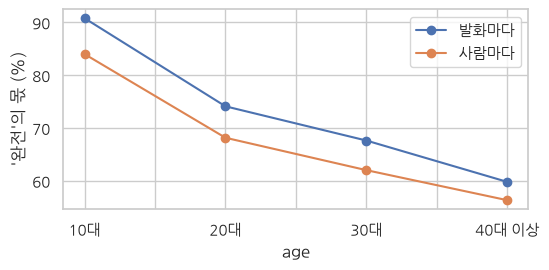

In [17]:
cmp = pd.DataFrame({'발화마다': age['완전%'],
                    '사람마다': p.groupby('age')['완전%'].mean()})
cmp.plot(marker='o', figsize=(6, 2.6), ylabel="'완전'의 몫 (%)")
plt.savefig('plots/wanjeon-age.png', dpi=150, bbox_inches='tight')

## 6. 용례 읽기

수 뒤에 있는 발화를 읽는다. 같은 `'아주'`를 10대와 40대 이상에서 넷씩 뽑는다.

- `show(a, w)`: 나이 `a`에서 낱말 `w`가 든 발화를 넷 고른다.
- `sample`: 행을 무작위로 고른다. `random_state`를 정해 두면 누가 돌려도 같은 넷이 나온다.

In [18]:
def show(a, w):
    s = u.loc[(u['age'] == a) & (u[w] > 0), 'form']
    for f in s.sample(4, random_state=0):
        print(f)
show('10대', '아주')

아주 조금씩 배우고 있...습니다
그니까 띵동와플 있을 땐 아주 좋았는데...
아주 코미디야
호텔델루나는 저는 안 봤지만 친구가 아주 좋아해서 이름은 알고 있습니다. 그 귀신 쉬면서 성불 도와주는걸로 알고있어요. 아이유님 나오시고.


40대 이상의 '아주'를 본다.

**같은 '아주'인데 결이 다르다.** 10대의 넷 가운데 둘에 격식체 '-습니다'가 있고, 40대 이상은 넷 다 반말이다. 넷으로 말할 수는 없지만 **세어 볼 물음**이 생겼다. 격식을 차린 말에서는 '아주'를 더 고르는가?

In [19]:
show('40대 이상', '아주')

뱃속이 아주~ 야물딱지네 
ㅋㅋㅋ 전방 15도 아주 세세하게 ㅋㅋ
이햐 에브리봇은 아주 쭉쭉 빠진다 ㅋㅋㅋ
name25이도 아주 괜찮다고 하네.


**세어 본다.** '습니다'가 든 발화인지를 참·거짓 열로 만들고, 그 열로 묶어 '완전'의 몫을 낸다. `share`를 다시 썼다.

'습니다'가 든 발화에서 '완전'의 몫은 25.8%, 나머지에서는 72.1%다. **그러나 89번뿐이다.** 게다가 '습니다'로는 '합니다', '입니다'를 못 찾는다. ㅂ이 음절 안에 들어 있기 때문이다(9강). 격식체를 무엇으로 찾을지부터 정해야 한다.

In [20]:
u['습니다'] = u['form'].str.contains('습니다')
f = u.groupby('습니다')[['완전', '아주']].sum()
f['완전%'] = share(f)
print(f.round(1))

         완전    아주   완전%
습니다                    
False  8613  3331  72.1
True     23    66  25.8


## 7. 왜 그럴까

젊을수록, 여성일수록 '완전'을 더 고른다. 수는 여기까지 말한다. 왜 그런지는 해석이고, 해석은 여럿일 수 있다.

**나이 — 시간으로 읽는다면.** 2021년의 10대는 대략 2000년대생, 40대 이상은 1970년대 이전에 태어났다.

| 2021년의 나이 | 10대 | 20대 | 30대 | 40대 이상 |
|---|---|---|---|---|
| 대략 태어난 때 | 2000년대 | 1990년대 | 1980년대 | 1970년대 이전 |
| '완전'의 몫 (%) | 90.8 | 74.1 | 67.6 | 59.8 |

- **변화가 진행 중이다.** 한 시점의 나이 차이를 시간에 따른 변화의 흔적으로 읽는 방법을 **겉보기 시간**(apparent time)이라 한다. 젊을수록 새 말을 많이 쓰면 변화가 진행 중이라고 본다. 김다미(2021)는 very의 '완전'이 활발해진 때를 1990년대 중후반 또는 2000년대 초로 보았다(464쪽). 그 뒤에 자란 세대일수록 '완전'을 더 고른다.
- **나이가 들며 바꾼다.** 사람이 나이가 들면서 강조 부사를 바꾸는 것일 수도 있다(**연령 단계**, age grading). 2021년 한 해의 말뭉치로는 이 둘을 가를 수 없다. 다른 해의 말뭉치와 비교해야 한다.
- **강조 부사는 닳는다.** 자주 쓰인 강조 부사는 뜻이 추상화되어 힘이 빠지고, 더 센 새 말이 그 자리에 든다. 김다미(2021)도 '완전'이 의미의 추상화를 겪고 있다고 보았다(453쪽 각주 11). 12강에서 '아주'는 '아주 조금', '아주 가끔'까지 꾸미는, 정도만 남은 닳은 쪽이었다. '완전'은 '똑같다', '다르다'와 어울리는 '모두, 두루'가 아직 남은 센 말이다. 영어에서도 *very*는 나이 든 화자에서만 가장 흔하고, *really*는 가장 젊은 세대에서 크게 늘었으며, 옛 강조 부사는 사라지지 않고 새것과 함께 쓰인다(Ito & Tagliamonte 2003, *Language in Society* 32(2), 257–279).

**성별 — 여성 쪽이 '완전'을 더 고르는 까닭.** 두 가지 읽기가 있다.

- **여성이 변화를 이끈다.** 지금까지의 사회언어학 연구에서 여성은 대체로 언어 변화를 앞서 이끌었다(Labov 1990, *Language Variation and Change* 2(2), 205–254). '완전'이 퍼지는 중이라면 같은 쪽이다.
- **여성이 강조를 더 한다.** 세종 구어 말뭉치에서 사적인 말에서는 여성이 강조 부사를 더 썼고, 공적인 말에서는 차이가 작았다(김혜영·강범모 2010, 《한국어학》 48, 101–129).

뒤의 읽기가 맞다면 여성은 '완전'과 '아주'를 합한 수부터 많아야 한다. 나이와 성별로 나누어 두 낱말을 합한 만 발화당 수를 낸다. 앞에서 만든 `both` 표에 열을 하나 더한다.

In [21]:
n = u.groupby(['age', 'sex']).size()
both['만 발화당'] = (both['완전'] + both['아주']) / n * 10000
print(both['만 발화당'].unstack().round(1))

sex       남성    여성
age               
10대     41.2  60.9
20대     43.1  42.9
30대     16.7  36.9
40대 이상  46.9  45.7


오늘의 수로는 20대와 40대 이상에서 강조를 **얼마나** 하는지가 남녀 거의 같다(43.1 대 42.9, 46.9 대 45.7). 그래도 두 나이 모두 '완전'의 몫은 여성 쪽이 크다(74.6 대 69.8, 61.2 대 51.5). 차이는 **무엇을** 고르는가에 있다.

**말투를 맞추어 보면.** 6절에서 '습니다'가 든 발화는 '아주'를 고르는 쪽이었다. 남성이 격식체를 더 쓴다면 남성의 몫이 낮아질 수 있다. 앞에서 만든 `'습니다'` 열을 다시 쓴다.

- 참·거짓 열의 `mean()`은 참의 비율이다.
- `~`는 참과 거짓을 뒤집는다. `u[~u['습니다']]`는 '습니다'가 없는 발화만 남긴다.

남성의 발화에는 '습니다'가 두 배 잦다(0.68% 대 0.32%). 그러나 '습니다' 발화를 빼도 **나이와 성별의 순서는 그대로**다. 다만 '습니다'는 격식체의 일부만 잡는다.

In [22]:
print(u.groupby('sex')['습니다'].mean().round(4).to_dict())
v = u[~u['습니다']]
print(share(v.groupby('age')[['완전', '아주']].sum()).round(1).to_dict())
print(share(v.groupby('sex')[['완전', '아주']].sum()).round(1).to_dict())

{'남성': 0.0068, '여성': 0.0032}
{'10대': 91.3, '20대': 74.4, '30대': 67.9, '40대 이상': 60.3}
{'남성': 66.6, '여성': 72.8}


## 다른 말뭉치로 확인하기

교수자가 **일상 대화 말뭉치 2025**(국립국어원, 버전 1.0)의 사적 대화 2,288건(화자 1,712명)을 같은 셈으로 세었다. 이 수업에서 신청한 말뭉치가 아니라서 코드는 싣지 않는다.

| | 온라인 대화 2021 (메신저) | 일상 대화 2025 (녹음 전사) |
|---|---|---|
| 사람 | `who`로 어림 | 화자 번호가 사람마다 하나 |
| 나이별 '완전'의 몫 | 90.8 → 59.8 (10대 → 40대 이상) | 71.2 → 5.2 (10대 → 60대 이상) |
| 사람마다 한 표로 | 84.0 → 56.3 | 68.7 → 7.8 |
| 성별 (여성 / 남성) | 72.5 / 65.9 | 24.9 / 16.6 |
| '습니다'가 든 발화 | 25.8 | 4.5 |

**방향은 같고, 수준은 다르다.** 젊을수록, 여성일수록 '완전'을 고르고, 격식체에서는 '아주'를 고른다. 그러나 20대만 보아도 74.1 대 47.9다. 2025년 대화는 절반 남짓이 처음 만난 사이로 보이고(관계 '기타', 연락 빈도 0), 몫은 처음 만난 사이 22.2, 친구 사이 61.2다. 매체도 달라서, 이 둘로는 변화와 나이 듦을 가를 수 없다.

## 해석을 가르려면

| 해석 | 오늘의 수 | 가르려면 |
|---|---|---|
| 변화가 진행 중 | 사람마다 세어도 젊을수록 몫이 크다 | 다른 해의 말뭉치를 같은 방법으로 |
| 나이 들며 바꾼다 | 위와 같은 수로도 설명된다 | 같은 사람들을 여러 해 따라가기 |
| 강조 부사의 교체 | '아주 조금', '아주 가끔'(12강) | 뜻의 세기를 따로 재기 |
| 여성이 변화를 이끈다 | 나이 안에서도 여성 쪽 몫이 크다 | 남성이 넉넉한 말뭉치 |
| 말투의 차이 | '습니다'를 빼도 순서가 같다 | 상대와 친밀도를 맞춘 비교 |

**해석은 가설이다.** 같은 수가 여러 해석과 함께 맞을 수 있다. 하나를 고르기보다 무엇을 세면 가를 수 있는지를 적어 둔다. 기말 프로젝트의 물음은 흔히 이런 자리에서 나온다.

## 이 수가 말하지 않는 것

- **누구의 말뭉치**: 모집에 응한 사람들의 대화다. 남성과 10대는 적고, 같은 사람이 여러 번 나온다.
- **사람**: `who`는 속성으로 어림한 사람이다. 실제로는 더 많거나 적을 수 있다.
- **자리**: '완전'과 '아주'가 둘 다 올 수 있는 자리만 센 것이 아니다.

그래서 보고서에는 12강에 적은 것(말뭉치, 찾은 방법)에 더해, 무엇을 열쇠로 이었는지, 무엇을 사람으로 쳤는지(`who`), 무엇으로 나누었는지(발화 수, 두 낱말의 합), 칸마다 몇 번이었는지를 적는다.

## 다음 시간

10월 26일(월)과 28일(수)은 언어데이터 관리 사례 발표다. 14강(11월 2일 월요일)에서는 JSON 다음으로 XML을 다룬다. 12강에서 웹 화면으로 찾아본 표준국어대사전을 이번에는 데이터 파일로 읽는다.

오늘처럼 말뭉치에서 셀 수 있는 물음을 하나 떠올려 두자. 누가, 무엇 앞에서, 얼마나 쓰는가. [숙제10] 기말프로젝트 주제 선정의 씨앗이 된다.